# Data Cleaning with Python

## Contents

* [Prerequisites](#Prerequisites)
* [Data quality aspects](#Data-quality-aspects)
  * [Data validity constraints](#Data-validity-constraints)
* [Data cleaning workflow](#Data-cleaning-workflow)
* [Data](#Data)
  * [Load the example dataset](#Load-the-example-dataset)
* [Data inspection](#Data-inspection)
  * [Checking variable validity](#Checking-variable-validity)
    * [General overview](#General-overview)
    * [Data-types](#Data-types)
    * [Duplicate items](#Duplicate-items)
    * [Ranges (of numerical variables)](#Ranges-(of-numerical-variables))
    * [Set memberships (of categorical variables)](#Set-memberships-(of-categorical-variables))
    * [Unique values](#Unique-values)
    * [Missing values](#Missing-values)
  * [Basic statistics](#Basic-statistics)
    * [Bivariate statistics](#Bivariate-statistics)
    * [Pivot tables](#Pivot-tables)
    * [Correlations](#Correlations)
  * [Data inspection by visualizations](#Data-inspection-by-visualizations)
    * [Categoricals](#Categoricals)
    * [Numerics](#Numerics)
    * [Bi-/Trivariate](#Bi-/Trivariate)
    * [Heat maps](#Heat-maps)
  * [Data inspection with data-profiling](#Data-inspection-with-data-profiling)
* [Explore cleaning](#Explore-cleaning)
  * [Dealing with insufficient data](#Dealing-with-insufficient-data)
  * [Removing data](#Removing-data)
  * [Correcting data](#Correcting-data)
    * [Change data-types](#Change-data-types)
      * [Change data-type of "age" into integer](#Change-data-type-of-"age"-into-integer)
      * [Transforming "999" in 'pdays' to NA/None](#Transforming-"999"-in-'pdays'-to-NA/None)
    * [Unify inconsistent, but equal values or aggregate variable levels](#Unify-inconsistent,-but-equal-values-or-aggregate-variable-levels)
      * [Aggregate levels of 'job' and 'education'](#Aggregate-levels-of-'job'-and-'education')
  * [Imputing data](#Imputing-data)
  * [Transforming data](#Transforming-data)
    * [Recode nominals into dummy variables](#Recode-nominals-into-dummy-variables)
    * [Recode ordinals as numeric](#Recode-ordinals-as-numeric)
  * [Standardize](#Standardize)
* [Define & verifying pipeline](#Define-&-verifying-pipeline)
* [Implementing & reporting](#Implementing-&-reporting)

Wanna find out about "Data Science Expectation vs Reality 🧐"?

![Data Science Expectation vs Reality](https://flinkliv.com/pages/image/advice/en/dataScience.png)

(Source: https://flinkliv.com/pages/advice.html)

Before any data analysis can take place, a certain **preprocessing** of data is necessary. And especially when you are dealing with "real world" data, there is good chance that your raw data will reveal **flaws like invalid, missing or doubtable values**, you have to address. That's what DATA CLEANING is for!

This notebook generally deals with **tabular data** and uses example data which reclines on a typical survey use case.

In this notebook you will learn
* which quality aspects of data are worth to look after
* how to to outline a data cleaning workflow
* ways to inspect your raw data with exploratory data analysis (EDA) methods
* to fulfill certain tasks of data cleaning like removing, correcting, transforming and imputing
* and to standardize your data, if needed.

Have fun!

## Prerequisites

In [1]:
!python --version

Python 3.13.16


In [2]:
# What do I need to install if no env is there? See environment.yml.
import yaml
with open('environment.yml', 'r') as stream:
    env = yaml.safe_load(stream)
env

{'name': 'cleaning-env',
 'channels': ['defaults', 'conda-forge'],
 'dependencies': ['pandas=1.4.*',
  'scikit-learn=1.0.*',
  'seaborn=0.11.*',
  'python=3.8.5',
  'ipython=8.0.*',
  'ipywidgets=7.6.*',
  'jupyterlab=2.2.*',
  'pip==22.0.*',
  {'pip': ['https://github.com/pandas-profiling/pandas-profiling/archive/master.zip']}],
 'prefix': 'C:\\Users\\kwoit\\Documents\\Github\\data-cleaning-with-python\\cleaning-env'}

In [3]:
# What is actually installed? Versions of the main packages
from importlib.metadata import version
for pkg in ['pandas', 'numpy', 'scikit-learn', 'seaborn', 'matplotlib', 'fg-data-profiling']:
    print(pkg, version(pkg))

pandas 2.3.3
numpy 2.5.4
scikit-learn 1.9.1
seaborn 0.13.2
matplotlib 3.11.2
fg-data-profiling 4.20.0


## Data quality aspects

The overall goal of data cleaning procedures is to raise the data quality to conducting reasonable research.
To find out about potential problems with the raw data, let us first reflect about quality aspects of data. There is

* **validity**, the degree to which the data conforms to defined business rules or constraints  
* **accuracy**, the degree to which the data is close to the true values.  A valid person's eye colour, say blue, might be valid, but not true, because it does not represent the reality.  
* **completeness**, the degree to which all required data is known  
* **consistency**, the degree to which the data is consistent, within the same data set or across multiple data sets  
* **uniformity**, the degree to which the data is specified using the same unit of measure.

Before taking a deeper look into data validity constraints we might clarify some terms that will occur along the notebook. For tabular data **several terms** are in use for the basic concepts of **rows** and **columns** due to different research areas like e.g. social sciences and data science. Here's a short overview about terms you might heard already:

![](tabular_data_terminology.png "Tabular Data Terminology")


### Data validity constraints
Tabular data in particular demands a set of data validity constraints, as these will form the **basis to perform statistical methods** in a correct way. Certain data values will have to conform to one or more constraints of their data field like:

* **data-type**, conformity to basic data types like boolean, numeric, text, date
* **uniqueness**, only unique values are allowed in a field, e.g. the *ID* value has to be unique
* **range**, values have to fall into a certain range of values, e.g. the *body temperature* has to be in the range of [30, 45] 
* **mandatory**, a field does not allow a NULL/None value, e.g. the *ID* field must not be empty
* **foreign-key**, a foreign-key field demands the existence of the referenced primary keys  
* **set-membership**, the value has to be one in a discrete set of values like [diverse, female, male] 
* **regular expression patterns**, which can be defined to specify a certain value format, e.g. the postal codes have to conform the the format of 'CH-xxxx'
* **cross-field validation**, conditions that span across multiple fields, like the value of *end date* has to be later then the one of *start date*.


## Data cleaning workflow
Data cleaning methods target the fulfilment of data quality aspects and especially data validity constraints. This means that **raw data will be turned into data, which is ready for research analysis**. Raw data will thus be modified, and for the sake of **soundness and reproducibility** it's essential to plan and **document your transformation steps**. And of course, before you start transformation, you need to know what fields and values need will need which transformation.

Here is a systematic way to go through your data cleaning task:

**1 Data inspection** 

* Detecting unexpected, incorrect, and inconsistent data.

**2 Explore cleaning**

* Finding proper methods to fix or remove the various anomalies discovered.
* Working in an exploratory and iterative way.
* Keeping track of the dependencies, which might occur while exploring different transformations. 

**3 Define & verifying pipeline**

* Construct an appropriate cleaning pipeline by bringing the necessary transformations in a working order.
* Verifying the correctness of the cleaning procedure with - maybe example - data.

**4 Implementing & reporting**

* Rolling-out the cleaning procedure and storing the resulting data.
* Reporting the transformation steps (and maybe their causes), the changes made and the characteristics of the resulting data.

## Data
Original data source is this machine learning dataset: [Bank Marketing Data Set](https://archive.ics.uci.edu/dataset/222/bank+marketing). It describes data (bank client and other attributes) used for marketing campaigns of a Portuguese banking institution. **Variable definitions** are available there: Please take a look at them!

Here, an abridged and adjusted set given in the *bank.csv* file will be used for training reasons.


In [4]:
# Load standard libraries
import numpy as np, pandas as pd        # for numeric/table data handling
import seaborn as sns       # for nice visualizations 

In [5]:
# Pandas version used
pd.__version__

'2.3.3'

### Load the example dataset

In [6]:
# Read CSV file into Pandas dataframe
data_path = '' 
df = pd.read_csv(data_path + 'bank.csv', sep=';')
df.tail(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
10360,39.0,admin.,married,university.degree,no,no,no,telephone,jul,mon,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.960,5228.1,yes
10361,44.0,services,single,high.school,no,yes,no,cellular,nov,wed,...,5,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no
10362,36.0,admin.,single,university.degree,no,no,no,telephone,may,mon,...,5,999,0,nonexistent,-1.8,92.893,-46.2,1.244,5099.1,no
10363,29.0,technician,single,professional.course,no,no,no,cellular,nov,fri,...,3,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,yes
10364,57.0,technician,married,university.degree,no,no,no,cellular,aug,thu,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.964,5228.1,no


## Data inspection

### Checking variable validity

Checking variable validity - that means looking for valid or invalid data-types and ranges, item duplicates, suitable set-memberships, values which should be unique or mandatory, unknown/missing values and so on.

But first, take general look at the data, like the extent of the dataframe and what columns are there at all.

#### General overview

In [7]:
# Dimensions of the dataframe
df.shape

(10365, 21)

In [8]:
# Dataframe shape, columns, data-types, number of non-NULL values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10365 entries, 0 to 10364
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             10324 non-null  float64
 1   job             10365 non-null  object 
 2   marital         10263 non-null  object 
 3   education       10365 non-null  object 
 4   default         10365 non-null  object 
 5   housing         10365 non-null  object 
 6   loan            10365 non-null  object 
 7   contact         10365 non-null  object 
 8   month           10365 non-null  object 
 9   day_of_week     10365 non-null  object 
 10  duration        10365 non-null  int64  
 11  campaign        10365 non-null  int64  
 12  pdays           10365 non-null  int64  
 13  previous        10365 non-null  int64  
 14  poutcome        10365 non-null  object 
 15  emp.var.rate    10365 non-null  float64
 16  cons.price.idx  10365 non-null  float64
 17  cons.conf.idx   10365 non-null 

In [9]:
# All dataframe columns
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [10]:
# Basic statistics for numeric variables
df.describe().round(1)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,10324.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0
mean,40.4,369.9,2.4,899.8,0.3,-0.4,93.5,-40.2,3.1,5140.3
std,11.8,349.5,2.5,297.8,0.7,1.7,0.6,5.3,1.9,85.8
min,17.0,0.0,1.0,0.0,0.0,-3.4,92.2,-50.8,0.6,4963.6
25%,31.0,136.0,1.0,999.0,0.0,-1.8,93.0,-42.7,1.3,5076.2
50%,38.0,252.0,2.0,999.0,0.0,-0.1,93.4,-41.8,4.1,5191.0
75%,48.0,493.0,3.0,999.0,0.0,1.4,94.0,-36.4,5.0,5228.1
max,98.0,4199.0,43.0,999.0,6.0,1.4,94.8,-26.9,5.0,5228.1


In [11]:
# Basic statistics for non-numeric variables (categoricals)
df.describe(exclude='number')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,10365,10263,10365,10365,10365,10365,10365,10365,10365,10365,10365
unique,12,4,8,2,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,2761,5973,3284,8658,5468,8603,7308,2912,2257,8259,5725


#### Data-types

In [12]:
# Datatypes of the columns
df.dtypes

age               float64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

In [13]:
# List of all categorical features
categoricals = df.select_dtypes(exclude='number').columns
categoricals

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')

In [14]:
# List of all numerical features
numericals = df.select_dtypes(include='number').columns
numericals

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

In [15]:
# List all columns with a certain datatype in a more informed way (with the number of non-NA's)
df.select_dtypes(include='float').info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10365 entries, 0 to 10364
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             10324 non-null  float64
 1   emp.var.rate    10365 non-null  float64
 2   cons.price.idx  10365 non-null  float64
 3   cons.conf.idx   10365 non-null  float64
 4   euribor3m       10365 non-null  float64
 5   nr.employed     10365 non-null  float64
dtypes: float64(6)
memory usage: 486.0 KB


Having *age* as a float number doesn't seem very reasonable. 

<span style="color:red"> *Possible cleaning action:* </span> Changing *age* to integer data-type.

In [16]:
# Inspect a certain dataframe section by selecting rows and columns
df.iloc[8538:8548, 0:12]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign
8538,35.0,technician,single,unknown,no,no,no,cellular,may,thu,745,1
8539,82.0,housemaid,married,basic.4y,no,no,no,telephone,sep,tue,279,3
8540,25.0,admin.,married,university.degree,no,no,no,cellular,mar,fri,243,3
8541,84.0,retired,divorced,basic.4y,no,yes,yes,cellular,jul,tue,666,1
8542,36.0,admin.,married,university.degree,unknown,yes,no,cellular,aug,wed,155,11
8543,38.0,technician,married,professional.course,no,no,no,cellular,may,tue,371,2
8544,36.0,technician,married,high.school,no,no,no,cellular,aug,fri,314,3
8545,32.0,admin.,single,basic.9y,no,no,no,cellular,jul,thu,185,1
8546,41.0,entrepreneur,married,basic.9y,no,no,yes,cellular,may,mon,285,2
8547,48.0,blue-collar,married,basic.4y,no,yes,no,cellular,may,wed,238,3


#### Duplicate items

In [17]:
# Number of unique combinations of columns = Number of unique rows
len(df.value_counts(dropna=False))

10364

In [18]:
# Find duplicate rows according to all columns
df[df.duplicated(subset=None, keep=False)==True]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
423,45.0,admin.,married,university.degree,no,no,no,cellular,jul,thu,...,1,999,0,nonexistent,-2.9,92.469,-33.6,1.072,5076.2,yes
4113,45.0,admin.,married,university.degree,no,no,no,cellular,jul,thu,...,1,999,0,nonexistent,-2.9,92.469,-33.6,1.072,5076.2,yes


Seems that there is a double entry for one observation.

<span style="color:red"> *Possible cleaning action:* </span> Deleting one of the double entries.

#### Ranges (of numerical variables)

In [19]:
print(df.age.min())
print(df.age.max())

17.0
98.0


In [20]:
# several columns at once
df[['emp.var.rate', 'cons.price.idx']].min()

emp.var.rate      -3.400
cons.price.idx    92.201
dtype: float64

In [21]:
# Some more basic statistics of "age"
df['age'].describe()

count    10324.000000
mean        40.359938
std         11.800919
min         17.000000
25%         31.000000
50%         38.000000
75%         48.000000
max         98.000000
Name: age, dtype: float64

In [22]:
# And of several features
df[['age', 'duration']].describe()

,age,duration
count,10324.000000,10365.000000
mean,40.359938,369.930439
std,11.800919,349.462228
min,17.000000,0.000000
25%,31.000000,136.000000
50%,38.000000,252.000000
75%,48.000000,493.000000
max,98.000000,4199.000000


In [23]:
# And of all numerical values in the dataframe, rounded
df.describe().round(1)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,10324.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0,10365.0
mean,40.4,369.9,2.4,899.8,0.3,-0.4,93.5,-40.2,3.1,5140.3
std,11.8,349.5,2.5,297.8,0.7,1.7,0.6,5.3,1.9,85.8
min,17.0,0.0,1.0,0.0,0.0,-3.4,92.2,-50.8,0.6,4963.6
25%,31.0,136.0,1.0,999.0,0.0,-1.8,93.0,-42.7,1.3,5076.2
50%,38.0,252.0,2.0,999.0,0.0,-0.1,93.4,-41.8,4.1,5191.0
75%,48.0,493.0,3.0,999.0,0.0,1.4,94.0,-36.4,5.0,5228.1
max,98.0,4199.0,43.0,999.0,6.0,1.4,94.8,-26.9,5.0,5228.1


Hint: Not only min and max, but sometimes also means and quartiles can be helpful to decide on data validity. In this example, all quartiles of *pdays* are "999". That should cause some curiosity. If not already done, that's the time to look at the [variable description](https://archive.ics.uci.edu/dataset/222/bank+marketing):

    pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)

So, "999" isn't a number here indeed, but a code for a None-value!

<span style="color:red"> *Possible cleaning action:* </span> Transforming "999" in column *pdays* to NA/None.

#### Set memberships (of categorical variables)

In [24]:
# Overview of categoricals with number of non-NA's, unique values ("levels") and
# top level with its count
df.describe(exclude='number')

,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,10365,10263,10365,10365,10365,10365,10365,10365,10365,10365,10365
unique,12,4,8,2,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,2761,5973,3284,8658,5468,8603,7308,2912,2257,8259,5725


In [25]:
# And of several features
df[['month', 'contact']].describe()

,month,contact
count,10365,10365
unique,10,2
top,may,cellular
freq,2912,7308


In [26]:
# Print levels of all categoricals with their occurences - without NAs
for i in df.select_dtypes(exclude='number'):
    print(i)
    print(df[i].value_counts())
    print('---')

job
job
admin.           2761
blue-collar      1966
technician       1704
services          914
management        720
retired           633
student           361
self-employed     360
entrepreneur      312
unemployed        281
housemaid         277
unknown            76
Name: count, dtype: int64
---
marital
marital
married     5973
single      3149
divorced    1121
unknown       20
Name: count, dtype: int64
---
education
education
university.degree      3284
high.school            2358
professional.course    1374
basic.9y               1321
basic.4y               1015
basic.6y                528
unknown                 479
illiterate                6
Name: count, dtype: int64
---
default
default
no         8658
unknown    1707
Name: count, dtype: int64
---
housing
housing
yes        5468
no         4642
unknown     255
Name: count, dtype: int64
---
loan
loan
no         8603
yes        1507
unknown     255
Name: count, dtype: int64
---
contact
contact
cellular     7308
telephone    305

In [27]:
# Levels of the variable "education" with occurences
df.education.value_counts()

education
university.degree      3284
high.school            2358
professional.course    1374
basic.9y               1321
basic.4y               1015
basic.6y                528
unknown                 479
illiterate                6
Name: count, dtype: int64

The level "illiterate" only appears six times. Maybe it is not useable to have a specific case here, but join it with "basic.4y" education - or with "unknown" education?

<span style="color:red"> *Possible cleaning action:* </span> Merge "illiterate" level items into "basic.4y" or "unknown" ones.

In [28]:
# Levels of the variable "job" in relative terms (proportions)
df.job.value_counts(normalize=True).round(2)

job
admin.           0.27
blue-collar      0.19
technician       0.16
services         0.09
management       0.07
retired          0.06
student          0.03
self-employed    0.03
entrepreneur     0.03
unemployed       0.03
housemaid        0.03
unknown          0.01
Name: proportion, dtype: float64

It is unclear what the difference is between "self-employed" and "entrepreneur" level. "admin." is the only value which is an abbreviation.

<span style="color:red"> *Possible cleaning actions:* </span> Merge "entrepreneur" level items into "self-employed" ones. Change "admin." into "administrative".

In [29]:
# Another way to get levels by grouping
df.groupby('marital').size()

marital
divorced    1121
married     5973
single      3149
unknown       20
dtype: int64

#### Unique values

In [30]:
# Unique values also include the NA/None category!
df.marital.unique()

array(['single', 'married', 'divorced', 'unknown', nan], dtype=object)

In [31]:
# Unique values can also be checked for numeric variables
df.pdays.unique()

array([999,   6,   3,   0,   8,  18,   7,   4,   2,   5,  12,  11,   9,
        10,  13,  15,  16,  26,   1,  14,  22,  17,  27,  25,  19,  21])

In [32]:
# Check, whether all values in a column are unique
len(df['cons.price.idx'].unique())==len(df['cons.price.idx'])

False

In [33]:
# Check, whether values of all columns are unique
[[i, len(df[i].unique())==len(df[i])] for i in df.columns]

[['age', False],
 ['job', False],
 ['marital', False],
 ['education', False],
 ['default', False],
 ['housing', False],
 ['loan', False],
 ['contact', False],
 ['month', False],
 ['day_of_week', False],
 ['duration', False],
 ['campaign', False],
 ['pdays', False],
 ['previous', False],
 ['poutcome', False],
 ['emp.var.rate', False],
 ['cons.price.idx', False],
 ['cons.conf.idx', False],
 ['euribor3m', False],
 ['nr.employed', False],
 ['y', False]]

#### Missing values

Missing values are a complex thing. First, it is crucial to understand the difference between "unknown" and not-given values. "Unknown" are qualified statements about the variable, for instance when the interviewee can't or won't answer the question.

Real missing values, also called "NULL" or "NA" (Not Available) on the contrary are non-existing values. These are referred to *None* or *NaN* in Python. While *None* is a certain Python object which forces a *object* data-type, *NaN*  (Not a Number) represents a missing floating-point value.
Both are to some extent interchangeable and can be addressed with the same commands.

In [34]:
# Number of missing values overall, detects NaN in numeric, None or NaN in object, NaT in datetime values
# Alternative: isna()
df.isnull().sum().sum()

np.int64(143)

In [35]:
# How many NA's are in a certain column (here: "marital")?
df.marital.isna().sum()

np.int64(102)

In [36]:
# Sum of all non-NA values
df.notna().sum().sum()

np.int64(217522)

In [37]:
# Number of missing values per column
# Alternative: isnull()
df.isna().sum()

age                41
job                 0
marital           102
education           0
default             0
housing             0
loan                0
contact             0
month               0
day_of_week         0
duration            0
campaign            0
pdays               0
previous            0
poutcome            0
emp.var.rate        0
cons.price.idx      0
cons.conf.idx       0
euribor3m           0
nr.employed         0
y                   0
dtype: int64

In [38]:
df.notnull().sum()

age               10324
job               10365
marital           10263
education         10365
default           10365
housing           10365
loan              10365
contact           10365
month             10365
day_of_week       10365
duration          10365
campaign          10365
pdays             10365
previous          10365
poutcome          10365
emp.var.rate      10365
cons.price.idx    10365
cons.conf.idx     10365
euribor3m         10365
nr.employed       10365
y                 10365
dtype: int64

In [39]:
 # Number of rows with missing values
df.shape[0] - df.dropna().shape[0]   

141

In [40]:
# Number of rows without any NAs
len(df.dropna())

10224

In [41]:
# Show all rows with NA in "age"
df[df['age'].isna()]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
122,NaN,admin.,married,university.degree,no,no,no,cellular,aug,thu,...,3,6,1,success,-1.7,94.027,-38.3,0.899,4991.6,yes
239,NaN,retired,married,basic.4y,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,yes
259,NaN,admin.,married,high.school,no,yes,no,telephone,may,mon,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
285,NaN,blue-collar,single,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,yes
504,NaN,student,single,high.school,no,yes,yes,cellular,may,tue,...,1,999,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,yes
572,NaN,unemployed,married,professional.course,no,no,no,telephone,may,tue,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
753,NaN,student,single,basic.9y,no,yes,no,cellular,aug,wed,...,1,4,1,success,-2.9,92.201,-31.4,0.879,5076.2,yes
1033,NaN,student,single,university.degree,no,yes,no,cellular,may,thu,...,1,999,0,nonexistent,-1.8,92.893,-46.2,1.266,5099.1,no
1057,NaN,blue-collar,single,basic.6y,no,no,no,cellular,jul,tue,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.961,5228.1,yes
1123,NaN,blue-collar,married,basic.6y,unknown,yes,no,cellular,may,wed,...,2,999,1,failure,-1.8,92.893,-46.2,1.334,5099.1,no


In [42]:
# Show all rows with one or more NA in any column
df[df.isna().any(axis=1)]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
95,34.0,admin.,NaN,high.school,no,yes,no,telephone,jun,mon,...,6,999,0,nonexistent,1.4,94.465,-41.8,4.961,5228.1,yes
122,NaN,admin.,married,university.degree,no,no,no,cellular,aug,thu,...,3,6,1,success,-1.7,94.027,-38.3,0.899,4991.6,yes
239,NaN,retired,married,basic.4y,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-0.1,93.200,-42.0,4.021,5195.8,yes
259,NaN,admin.,married,high.school,no,yes,no,telephone,may,mon,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
285,NaN,blue-collar,single,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9627,36.0,entrepreneur,NaN,university.degree,no,no,no,cellular,jul,wed,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,yes
9748,39.0,entrepreneur,NaN,high.school,no,unknown,unknown,telephone,jun,mon,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.960,5228.1,no
9854,NaN,management,single,university.degree,no,yes,no,telephone,may,tue,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,yes
10089,NaN,technician,divorced,professional.course,no,no,no,telephone,jun,wed,...,2,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no


### Basic statistics

#### Bivariate statistics

In [43]:
# Crosstab of categorical variables
pd.crosstab(df.job, df.education)

education,basic.4y,basic.6y,basic.9y,high.school,illiterate,professional.course,university.degree,unknown
job,,,,,,,,
admin.,25,29,131,823,0,98,1582,73
blue-collar,469,314,732,228,2,115,21,85
entrepreneur,27,17,39,42,1,31,142,13
housemaid,127,17,19,48,0,21,34,11
management,11,23,32,59,0,23,542,30
retired,241,20,41,98,2,85,97,49
self-employed,28,4,51,22,1,40,206,8
services,26,60,86,604,0,50,50,38
student,11,8,44,147,0,19,54,78


In [44]:
# Works also with numeric variables
pd.crosstab(df.marital, df.age).round()

age,17.0,18.0,19.0,20.0,21.0,22.0,23.0,24.0,25.0,26.0,...,83.0,84.0,85.0,86.0,87.0,88.0,89.0,92.0,94.0,98.0
marital,,,,,,,,,,,,,,,,,,,,,
divorced,0,0,0,0,0,0,0,2,5,3,...,5,2,2,0,1,9,2,1,0,0
married,0,0,0,0,4,0,6,24,33,49,...,4,1,6,4,0,0,0,2,1,2
single,3,13,24,31,35,46,69,130,118,151,...,0,0,0,1,0,0,0,0,0,0
unknown,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [45]:
# Grouped basic statistics
df.groupby(['marital','housing']).size()

marital   housing
divorced  no          495
          unknown      31
          yes         595
married   no         2697
          unknown     148
          yes        3128
single    no         1389
          unknown      74
          yes        1686
unknown   no           12
          yes           8
dtype: int64

In [46]:
# Grouped basic statistics in relative terms (proportions)
df[['marital', 'housing']].value_counts(normalize=True)

marital   housing
married   yes        0.304784
          no         0.262789
single    yes        0.164279
          no         0.135341
divorced  yes        0.057975
          no         0.048232
married   unknown    0.014421
single    unknown    0.007210
divorced  unknown    0.003021
unknown   no         0.001169
          yes        0.000779
Name: proportion, dtype: float64

In [47]:
# Grouped basic statistics (here: minima) of one variable ("age")
df.age.groupby(df.marital).min()

marital
divorced    24.0
married     21.0
single      17.0
unknown     25.0
Name: age, dtype: float64

In [48]:
# Multi grouped (= according to 2 or more variables) basic statics (here: mean)
df.groupby(['housing','marital']).mean(numeric_only=True).round(1)

age  duration  campaign  pdays  previous  emp.var.rate  \
housing marital                                                             
no      divorced  46.5     370.0       2.4  910.7       0.3          -0.2   
        married   43.2     377.2       2.4  912.8       0.3          -0.2   
        single    32.6     369.5       2.4  888.9       0.3          -0.6   
        unknown   38.5     520.8       3.7  751.0       0.5          -0.7   
unknown divorced  44.9     264.1       3.5  966.9       0.1           0.1   
        married   43.8     364.4       2.1  911.8       0.3          -0.3   
        single    32.8     361.8       2.4  851.4       0.4          -0.8   
yes     divorced  47.0     367.1       2.3  905.5       0.3          -0.3   
        married   43.5     367.1       2.5  905.3       0.3          -0.3   
        single    32.3     367.4       2.3  868.9       0.3          -0.8   
        unknown   41.5     452.4       2.8  999.0       0.2          -0.1   

                  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
housing marital                                                          
no      divorced            93.6          -40.3        3.3       5148.1  
        married             93.6          -39.9        3.3       5149.8  
        single              93.5          -40.3        2.8       5129.3  
        unknown             93.4          -38.2        2.6       5122.9  
unknown divorced            93.6          -40.2        3.5       5158.8  
        married             93.6          -40.2        3.1       5141.6  
        single              93.5          -40.5        2.6       5114.2  
yes     divorced            93.5          -40.6        3.1       5142.4  
        married             93.5          -40.1        3.2       5145.2  
        single              93.4          -40.7        2.6       5121.8  
        unknown             93.3          -39.8        3.5       5174.0

#### Pivot tables

In [49]:
# Pivot table
df.pivot_table(index='marital', columns='education', values='age').round(1)

education,basic.4y,basic.6y,basic.9y,high.school,illiterate,professional.course,university.degree,unknown
marital,,,,,,,,
divorced,61.3,45.8,41.8,44.2,42.0,44.8,44.5,55.4
married,51.1,41.1,41.4,41.3,54.8,43.1,41.8,50.0
single,36.6,32.6,32.6,31.0,51.0,33.1,33.1,30.5
unknown,53.0,54.0,49.0,28.0,NaN,NaN,35.9,40.3


#### Correlations

In [50]:
# Pearson correlation of 2 variables
df.loc[:, ['euribor3m', 'nr.employed']].corr()

,euribor3m,nr.employed
euribor3m,1.000000,0.941777
nr.employed,0.941777,1.000000


Highly correlated variables may be a problem while performing a regression analysis.

<span style="color:red"> *Possible cleaning action:* </span> Remove one of the two variables 'euribor3m' or 'nr.employed'.

In [51]:
# Spearman correlation of all numeric values
df.corr('spearman', numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.000000,-0.014014,-0.000095,-0.019991,0.016291,0.026014,0.033021,0.115391,0.017661,0.012921
duration,-0.014014,1.000000,-0.038442,-0.062881,0.040141,-0.054214,-0.003406,-0.036588,-0.079588,-0.087285
campaign,-0.000095,-0.038442,1.000000,0.089929,-0.111835,0.188311,0.116366,-0.019487,0.176185,0.180710
pdays,-0.019991,-0.062881,0.089929,1.000000,-0.684647,0.288172,0.029684,-0.150541,0.407503,0.430389
previous,0.016291,0.040141,-0.111835,-0.684647,1.000000,-0.424644,-0.169246,0.055799,-0.517635,-0.522247
emp.var.rate,0.026014,-0.054214,0.188311,0.288172,-0.424644,1.000000,0.718146,0.000915,0.902124,0.877933
cons.price.idx,0.033021,-0.003406,0.116366,0.029684,-0.169246,0.718146,1.000000,0.033907,0.449825,0.366736
cons.conf.idx,0.115391,-0.036588,-0.019487,-0.150541,0.055799,0.000915,0.033907,1.000000,-0.057230,-0.072179
euribor3m,0.017661,-0.079588,0.176185,0.407503,-0.517635,0.902124,0.449825,-0.057230,1.000000,0.948462
nr.employed,0.012921,-0.087285,0.180710,0.430389,-0.522247,0.877933,0.366736,-0.072179,0.948462,1.000000


In [52]:
# Kendall Tau correlation, grouped by 'marital'
df.groupby('marital').corr('kendall', numeric_only=True)

age  duration  campaign     pdays  previous  \
marital                                                                     
divorced age             1.000000  0.008581  0.005800 -0.140901  0.124342   
         duration        0.008581  1.000000 -0.016367 -0.041785  0.044811   
         campaign        0.005800 -0.016367  1.000000  0.023034 -0.032025   
         pdays          -0.140901 -0.041785  0.023034  1.000000 -0.639923   
         previous        0.124342  0.044811 -0.032025 -0.639923  1.000000   
         emp.var.rate   -0.126881 -0.052237  0.134301  0.254755 -0.380550   
         cons.price.idx  0.009233 -0.023474  0.079897 -0.005003 -0.125038   
         cons.conf.idx   0.099765 -0.053767 -0.016182 -0.146387  0.020993   
         euribor3m      -0.157841 -0.051862  0.113733  0.324132 -0.422400   
         nr.employed    -0.170148 -0.065473  0.115389  0.377089 -0.476234   
married  age             1.000000  0.000427 -0.029265 -0.093499  0.093278   
         duration        0.000427  1.000000 -0.028241 -0.057997  0.033383   
         campaign       -0.029265 -0.028241  1.000000  0.080831 -0.107688   
         pdays          -0.093499 -0.057997  0.080831  1.000000 -0.651993   
         previous        0.093278  0.033383 -0.107688 -0.651993  1.000000   
         emp.var.rate   -0.064950 -0.050637  0.163791  0.271341 -0.393442   
         cons.price.idx -0.029072 -0.016180  0.099489  0.050225 -0.175150   
         cons.conf.idx   0.117711 -0.016115  0.005078 -0.105227  0.013599   
         euribor3m      -0.067317 -0.060204  0.139583  0.323078 -0.424704   
         nr.employed    -0.085253 -0.072875  0.152488  0.364167 -0.462269   
single   age             1.000000 -0.022345  0.038111  0.094003 -0.095282   
         duration       -0.022345  1.000000 -0.036955 -0.037520  0.024219   
         campaign        0.038111 -0.036955  1.000000  0.096508 -0.112255   
         pdays           0.094003 -0.037520  0.096508  1.000000 -0.670241   
         previous       -0.095282  0.024219 -0.112255 -0.670241  1.000000   
         emp.var.rate    0.112613 -0.006798  0.138918  0.206595 -0.300043   
         cons.price.idx  0.039161  0.034553  0.068688 -0.020199 -0.085503   
         cons.conf.idx   0.000533 -0.024595 -0.046881 -0.157741  0.110039   
         euribor3m       0.123988 -0.036504  0.127688  0.335096 -0.412363   
         nr.employed     0.144435 -0.048208  0.144914  0.378713 -0.447656   
unknown  age             1.000000  0.224628  0.279103  0.431383 -0.163824   
         duration        0.224628  1.000000 -0.057487  0.019745 -0.024183   
         campaign        0.279103 -0.057487  1.000000 -0.011981  0.234787   
         pdays           0.431383  0.019745 -0.011981  1.000000 -0.665294   
         previous       -0.163824 -0.024183  0.234787 -0.665294  1.000000   
         emp.var.rate    0.326737  0.151668  0.184068  0.330015 -0.436704   
         cons.price.idx  0.251495  0.087997  0.367107  0.247594 -0.395896   
         cons.conf.idx  -0.195607  0.098997  0.006675 -0.433289  0.345356   
         euribor3m       0.276424  0.069339  0.038839  0.450225 -0.563665   
         nr.employed     0.389956  0.112173  0.078815  0.498342 -0.605820   

                         emp.var.rate  cons.price.idx  cons.conf.idx  \
marital                                                                
divorced age                -0.126881        0.009233       0.099765   
         duration           -0.052237       -0.023474      -0.053767   
         campaign            0.134301        0.079897      -0.016182   
         pdays               0.254755       -0.005003      -0.146387   
         previous           -0.380550       -0.125038       0.020993   
         emp.var.rate        1.000000        0.533536       0.016853   
         cons.price.idx      0.533536        1.000000       0.047314   
         cons.conf.idx       0.016853        0.047314       1.000000   
         euribor3m           0.781400        0.320649      -0.023820   
   

### Data inspection by visualizations

In [53]:
# Configure visualization settings, here: use matplotlib style for genuine Pandas plots
import matplotlib.pyplot as plt
%matplotlib inline

#### Categoricals

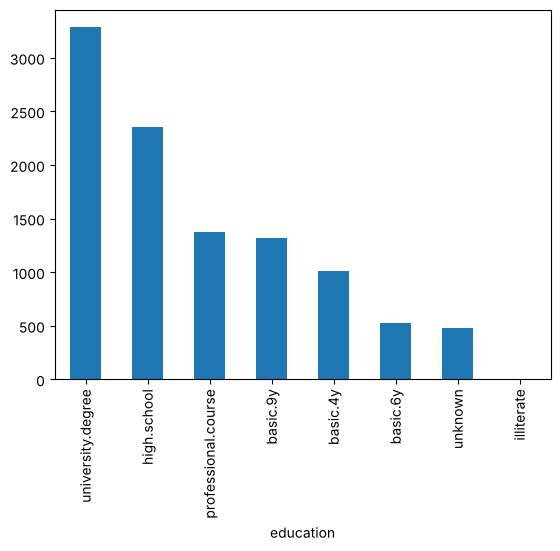

In [54]:
# Categorical: Bar chart
ax = df.education.value_counts().plot(kind='bar')

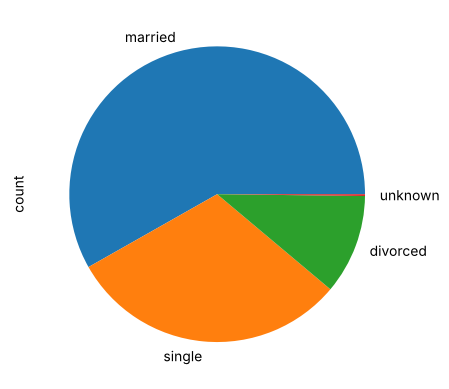

In [55]:
# Pie chart
ax = df.marital.value_counts().plot(kind='pie')

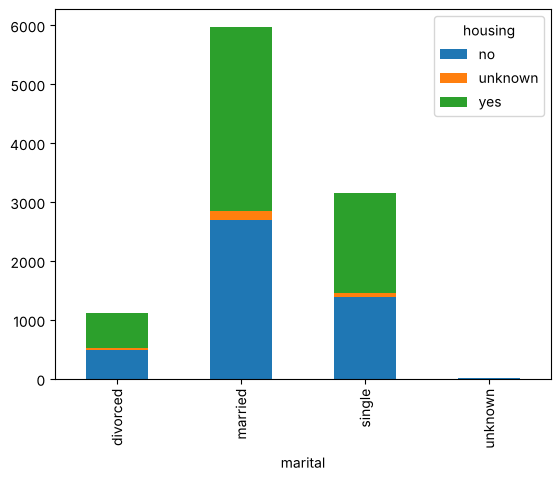

In [56]:
# Categorical & categorical: Stacked bar chart
ax = df.groupby(['marital', 'housing']).size().unstack().plot(kind='bar',stacked=True)

#### Numerics

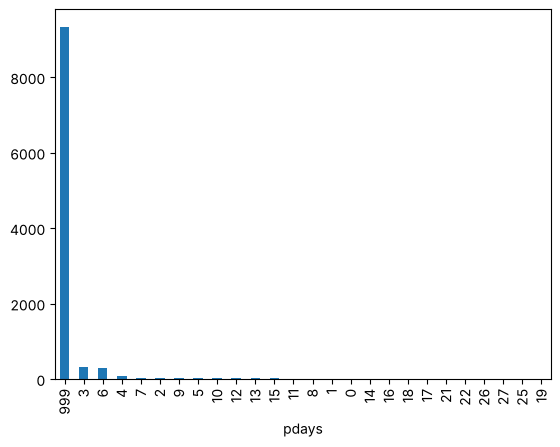

In [57]:
# Barchart
ax = df.pdays.value_counts().plot(kind='bar')

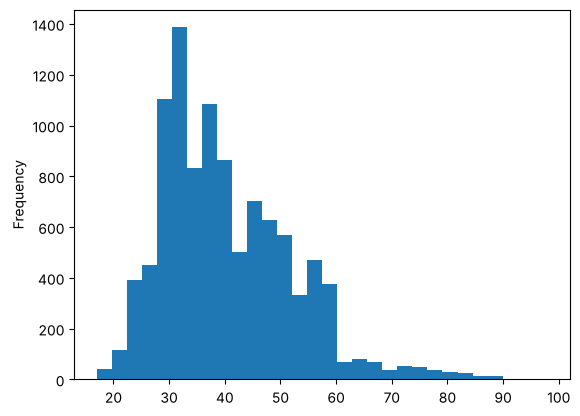

In [58]:
# Histogram
ax = df.age.plot(kind='hist', bins=30)

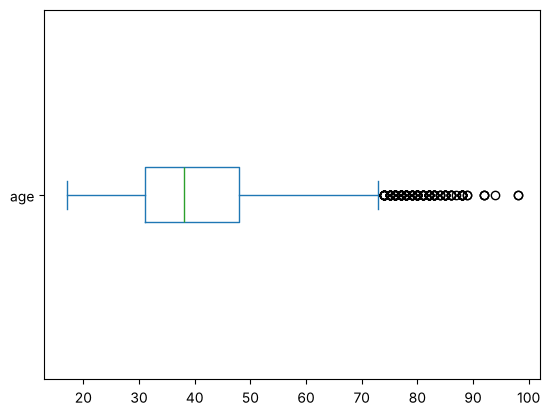

In [59]:
# Box-whiskers plot
ax = df.age.plot(kind='box', vert=False)

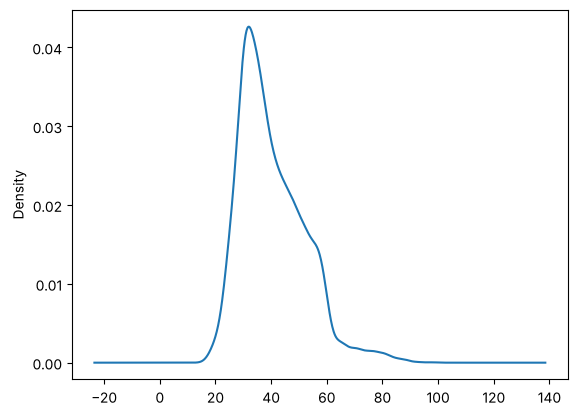

In [60]:
# Density plot
ax = df.age.plot(kind='density')

#### Bi-/Trivariate

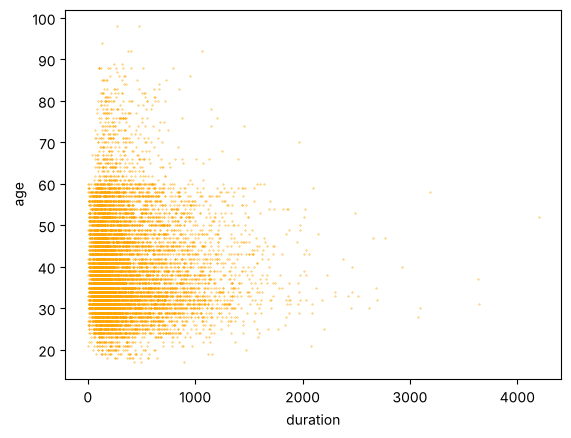

In [61]:
# Scatterplot
ax = df.plot.scatter(x='duration' , y='age', c='orange', s=0.1)

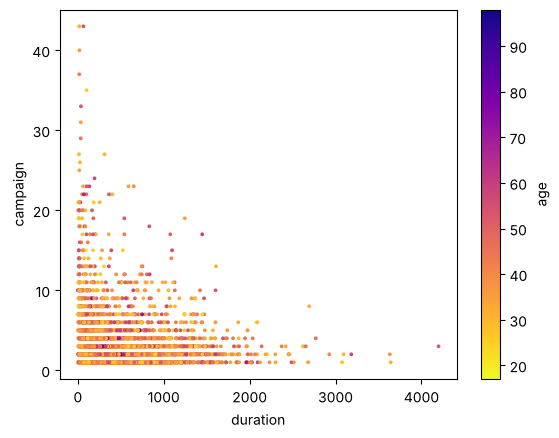

In [62]:
# Scatterplot with 3 numerics
ax = df.plot.scatter(x='duration' , y='campaign', c='age', cmap='plasma_r', s=3)

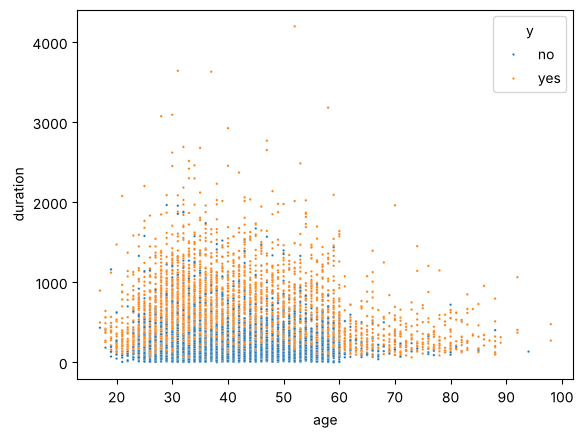

In [63]:
# Scatterplot with seaborn
ax = sns.scatterplot(x='age', y='duration', data=df, hue='y', s=3)

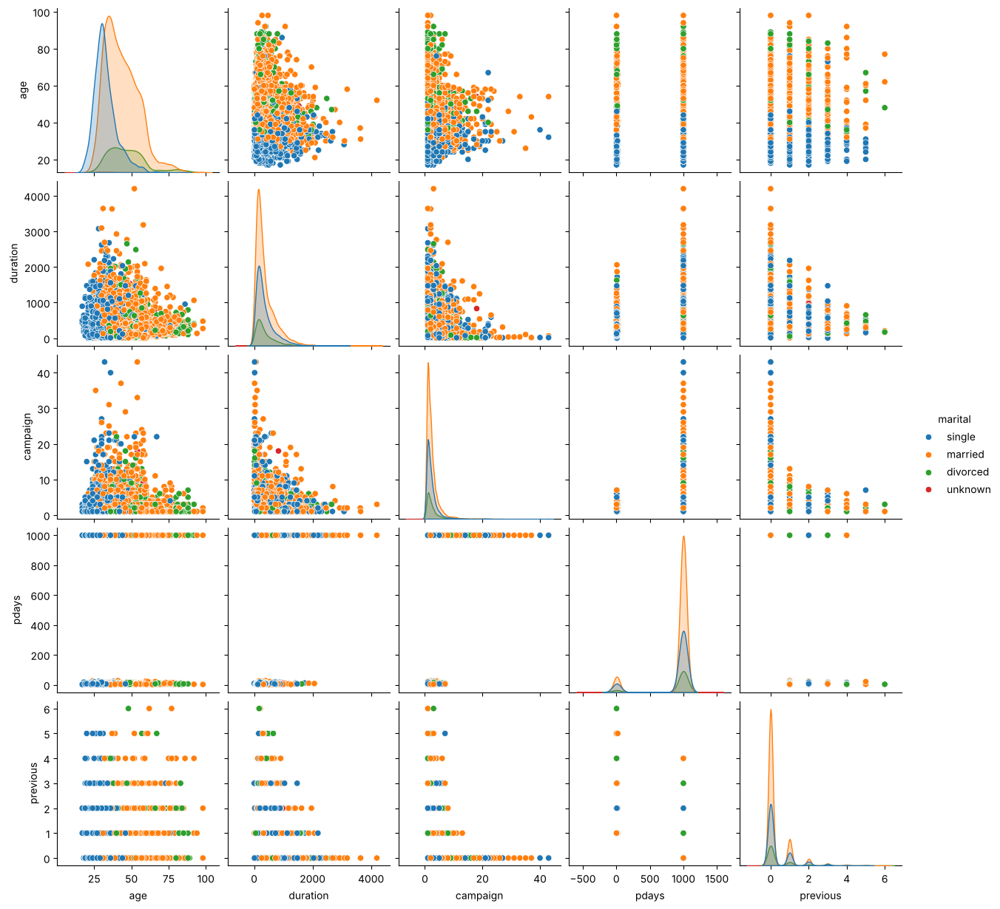

In [64]:
# Pair plot aka scatter plot matrix, here with "marital" groups) with seaborn
tmp_df = df.iloc[:, 0:15]
ax = sns.pairplot(tmp_df, hue='marital')

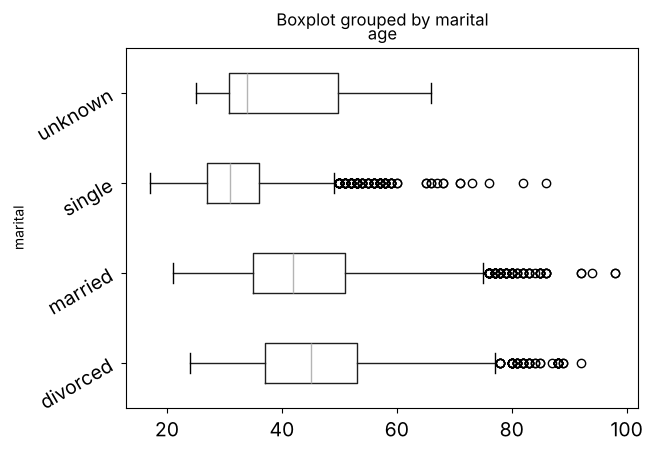

In [65]:
# Numeric & categorical: Grouped boxplot
ax = df.boxplot(column='age', by='marital', vert=False, grid=False, rot=30, fontsize=14)

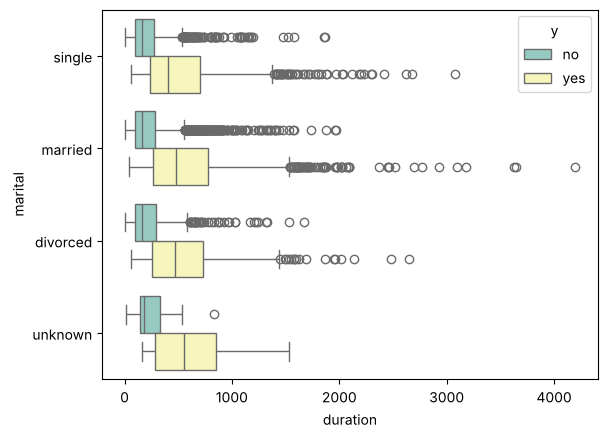

In [66]:
# Grouped boxplot with seaborn
ax = sns.boxplot(y='marital', x='duration', hue='y', data=df, orient='h', palette='Set3')

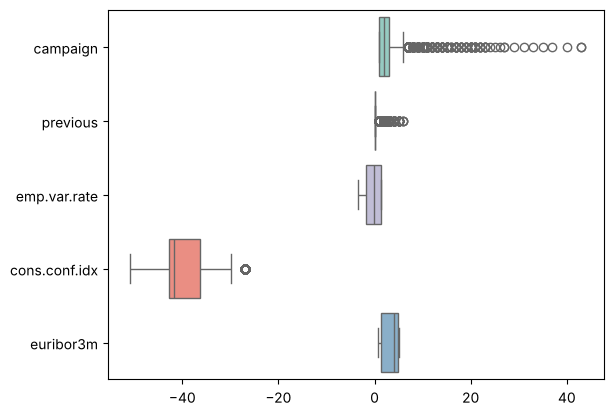

In [67]:
# Compound boxplot for several numeric values
tmp_df = df.drop(['nr.employed', 'duration', 'pdays', 'age', 'cons.price.idx'], axis=1)
ax = sns.boxplot(data=tmp_df, orient='h', palette='Set3')

#### Heat maps

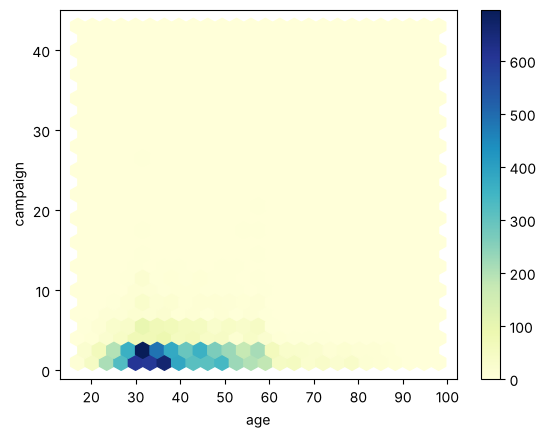

In [68]:
#  Hexagonal binning plot
ax = df.plot.hexbin(x='age', y='campaign', gridsize=25, cmap='YlGnBu')

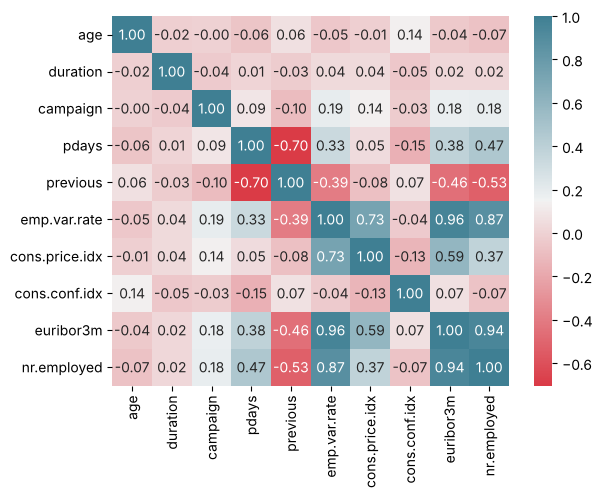

In [69]:
# Numerics' correlations as heatmap
corr = df.select_dtypes(include='number').corr()
ax = sns.heatmap(corr, annot=True, fmt='.2f', xticklabels=corr.columns, yticklabels=corr.columns,
                cmap=sns.diverging_palette(10, 220, as_cmap=True))

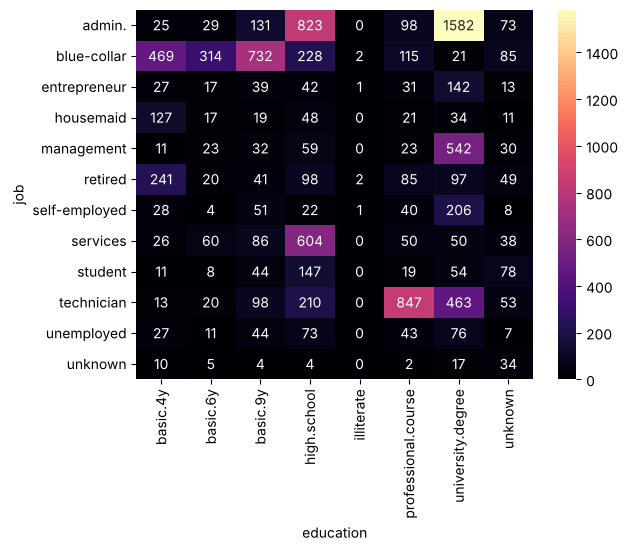

In [70]:
# Categoricals' crosstab as heatmap
ct = pd.crosstab( df['job'], df['education'])
ax = sns.heatmap(ct, annot=True, fmt='d', cmap='magma')

### Data inspection with data-profiling

The package formerly known as *pandas-profiling* (later *ydata-profiling*) is now called [fg-data-profiling](https://github.com/Data-Centric-AI-Community/fg-data-profiling). It creates a complete overview report of a dataframe with one command.

In [71]:
# Load package
from data_profiling import ProfileReport

In [72]:
profile = ProfileReport(df, title="Data Profiling")

In [73]:
profile.to_notebook_iframe()       # render the report inside the notebook

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:00<00:00, 217.30it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [74]:
# Optional: save the report as HTML file to open it in the browser
# profile.to_file("bank_profile.html")

## Explore cleaning

### Dealing with insufficient data

To deal with insufficient data there are generally several options:

* Removing
* Correcting
* Imputing
* Transforming & squeezing.

While showing different data transformations a derivative dataframe *tmp_df* will be used.

### Removing data

In [75]:
# Delete the duplicate row and reset index
tmp_df = df.drop_duplicates(subset=None, keep='first').reset_index(drop=True)
tmp_df.shape

(10364, 21)

In [76]:
# Remove whole columns, here "y" and "euribor3m"
print(len(df.columns))
tmp_df = df.drop(['y', 'euribor3m'], axis=1)
print(len(tmp_df.columns))

21
19


In [77]:
# Remove rows due to a constraint, e.g. a certain column value
print(df.housing.unique())
tmp_df = df[(df['housing'] != 'unknown')]
print(tmp_df.shape)
print(tmp_df.housing.unique())

['no' 'unknown' 'yes']
(10110, 21)
['no' 'yes']


### Correcting data

#### Change data-types

##### Change data-type of "age" into integer

In [78]:
# Change datatype
print(df.age.dtype)
# First: Let out rows with NAs in 'age', then change datatype of 'age'
tmp_df = df.dropna(subset=['age']).astype({'age': 'int64'})     
print(tmp_df.age.dtype)

float64
int64


In [79]:
# Alternative: Transform 'age' to Pandas Int64 data-type (instead of 'int 64', which is genuine NumPy)
print(df.age.dtype)
tmp_df = df.copy()     
tmp_df['age'] = tmp_df['age'].astype('Int64')
print(tmp_df.age.dtype)

float64
Int64


#####  Transforming "999" in 'pdays' to NA/None

*None* and *NaN* are Pandas' ways to mark non-values aka NA's. Both can be used nearly interchangeably as Pandas will cast the right flavour according to it's accompanying values. If there are string/categorical around (Pandas type *object*), the NA value will be *None*, if there are numericals, it will be *NaN* (and integer types will be changed to float).

In [80]:
df['pdays'].dtype

dtype('int64')

In [81]:
# Replace the code 999 by NaN in the whole column at once
tmp_df = df.copy()
tmp_df['pdays'] = tmp_df['pdays'].replace(999, np.nan)

In [82]:
# Original univariate description of "pdays"
df.pdays.describe()

count    10365.000000
mean       899.833092
std        297.756863
min          0.000000
25%        999.000000
50%        999.000000
75%        999.000000
max        999.000000
Name: pdays, dtype: float64

In [83]:
# A more reasonable univariate description of "pdays"
tmp_df.pdays.describe()

count    1035.000000
mean        5.893720
std         3.735748
min         0.000000
25%         3.000000
50%         6.000000
75%         6.000000
max        27.000000
Name: pdays, dtype: float64

In [84]:
# Sample view inside "pdays"
tmp_df.pdays[67:71]

67    3.0
68    6.0
69    NaN
70    NaN
Name: pdays, dtype: float64

#### Unify inconsistent, but equal values or aggregate variable levels

##### Aggregate levels of 'job' and 'education'

In [85]:
# unique values
print(df.job.unique())
print('----')
print(df.job.value_counts())

['admin.' 'blue-collar' 'technician' 'housemaid' 'retired' 'unemployed'
 'services' 'student' 'unknown' 'management' 'self-employed'
 'entrepreneur']
----
job
admin.           2761
blue-collar      1966
technician       1704
services          914
management        720
retired           633
student           361
self-employed     360
entrepreneur      312
unemployed        281
housemaid         277
unknown            76
Name: count, dtype: int64


In [86]:
# Merge similar/equal levels of "education" and "job"
tmp_df = df.copy()
tmp_df.education = tmp_df.education.replace('illiterate', 'basic.4y')
tmp_df.job = tmp_df.job.replace({'entrepreneur': 'self-employed', 'admin.': 'administrative'})

In [87]:
print(df.education.unique())
print(tmp_df.education.unique())

['university.degree' 'high.school' 'professional.course' 'basic.4y'
 'basic.9y' 'unknown' 'basic.6y' 'illiterate']
['university.degree' 'high.school' 'professional.course' 'basic.4y'
 'basic.9y' 'unknown' 'basic.6y']


In [88]:
print(df.job.unique())
print(tmp_df.job.unique())

['admin.' 'blue-collar' 'technician' 'housemaid' 'retired' 'unemployed'
 'services' 'student' 'unknown' 'management' 'self-employed'
 'entrepreneur']
['administrative' 'blue-collar' 'technician' 'housemaid' 'retired'
 'unemployed' 'services' 'student' 'unknown' 'management' 'self-employed']


### Imputing data

Imputing missing values means to infer these values from the known part of the data. Thus, missing values resp their rows and/or columns don't have to be discarded from analysis when using machine learning algorithms.
Imputing can be done manually using the *replace* method of Pandas and suitable statistics e.g. mean or median value for numerics and mode value for categoricals.
Imputing can also be done in a more automatically and conveniently way with the [scikit-learn.impute](https://scikit-learn.org/stable/modules/impute.html) module. 

Here, several methods are available:
* Univariate imputing (SimpleImputer): Use the non-missing values of the feature in question.
* Multivariate imputing (IterativeImputer):  Use the entire set of available features to estimate the missing values.
* Imputing using a k-Nearest-Neighbor classifier (KNNImputer): Use the values of the k most similar rows (nearest neighbours).

In [89]:
# NAs and mode value of "marital"
print(df.marital.unique())
print(df.marital.isna().sum())
print(df.marital.mode())

['single' 'married' 'divorced' 'unknown' nan]
102
0    married
Name: marital, dtype: object


In [90]:
# Categorical: Fill NA with mode values, manually
tmp_df = df.copy()
tmp_df['marital'] = tmp_df['marital'].fillna(tmp_df['marital'].mode()[0])
print(df.marital.value_counts())
print('----')
print(tmp_df.marital.value_counts())

marital
married     5973
single      3149
divorced    1121
unknown       20
Name: count, dtype: int64
----
marital
married     6075
single      3149
divorced    1121
unknown       20
Name: count, dtype: int64


In [91]:
df.age.isna().sum()

np.int64(41)

In [92]:
# Numeric: fill NA with mean values, manually
tmp_df = df.copy()
tmp_df['age'] = tmp_df['age'].fillna(tmp_df['age'].mean())
tmp_df.age.isna().sum()

np.int64(0)

In [93]:
# Categorical: fill NA with mode values, with scikit-learn Simple Imputer
# here: only one certain column to impute
from sklearn.impute import SimpleImputer
tmp_df = df.copy()

# Instantiate imputer
imp_mode = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
# Transform only 'marital' column (double brackets select a one-column dataframe)
tmp_df[['marital']] = imp_mode.fit_transform(tmp_df[['marital']])
print(tmp_df['marital'].value_counts())

marital
married     6075
single      3149
divorced    1121
unknown       20
Name: count, dtype: int64


In [94]:
# Numeric: fill NA with mean values, with Scikit-learn Simple Imputer
# Here: treat ALL numeric columns with NAs
from sklearn.impute import SimpleImputer

# Select all numeric columns for imputing
tmp_df = df.select_dtypes(include='number').copy()
print(tmp_df.isna().sum())
print(tmp_df.age.describe())
print('----')

# Instantiate imputer
imp_mean = SimpleImputer(missing_values=np.nan, strategy='mean')
# Imputer works on NumPy array
tmp_df = pd.DataFrame(imp_mean.fit_transform(tmp_df), columns=tmp_df.columns)

print(tmp_df.isna().sum())
# mean is the same, standard deviation has changed
print(tmp_df.age.describe())   

age               41
duration           0
campaign           0
pdays              0
previous           0
emp.var.rate       0
cons.price.idx     0
cons.conf.idx      0
euribor3m          0
nr.employed        0
dtype: int64
count    10324.000000
mean        40.359938
std         11.800919
min         17.000000
25%         31.000000
50%         38.000000
75%         48.000000
max         98.000000
Name: age, dtype: float64
----
age               0
duration          0
campaign          0
pdays             0
previous          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
dtype: int64
count    10365.000000
mean        40.359938
std         11.777554
min         17.000000
25%         31.000000
50%         38.000000
75%         48.000000
max         98.000000
Name: age, dtype: float64


### Transforming data

#### Recode nominals into dummy variables

In [95]:
# Recode nominals (one-hot encoding) via dummy variables, manually
tmp_df = df.copy()

# First level of "marital", "divorced" will be omitted
tmp_df = pd.get_dummies(tmp_df, columns=['marital'], drop_first=True)
tmp_df.iloc[0:5, 17:23]

,euribor3m,nr.employed,y,marital_married,marital_single,marital_unknown
0,1.405,5099.1,no,False,True,False
1,0.873,5076.2,no,True,False,False
2,4.962,5228.1,yes,True,False,False
3,1.405,5099.1,yes,True,False,False
4,4.957,5228.1,yes,False,True,False


#### Recode ordinals as numeric

In [96]:
# Recode ordinals with OrdinalEncoder (orders levels alphabetically)
from sklearn.preprocessing import OrdinalEncoder

# Instantiate encoder
enc = OrdinalEncoder()          
tmp_df = df.copy()
print(tmp_df['education'][60:65])
print('----')

tmp_df[['education']] = enc.fit_transform(tmp_df[['education']])
print(tmp_df['education'][60:65])
print('----')
# Show coded levels
print(enc.categories_)

60      university.degree
61    professional.course
62               basic.6y
63    professional.course
64      university.degree
Name: education, dtype: object
----
60    6.0
61    5.0
62    1.0
63    5.0
64    6.0
Name: education, dtype: float64
----
[array(['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate',
       'professional.course', 'university.degree', 'unknown'],
      dtype=object)]


In [97]:
# Recoding ordinals to numeric levels, manually
tmp_df = df.copy()

education_levels = {
    'illiterate' : 0,
    'unknown' : 0,      # possible decision: unite level 'unknown' with 'illiterate'
    'basic.4y' : 1,
    'basic.6y' : 2,
    'basic.9y' : 3,
    'professional.course' : 4,
    'high.school' : 5,
    'university.degree' : 6}

tmp_df['education'] = tmp_df['education'].map(education_levels)
print(df.education.value_counts())
print('----')
print(tmp_df.education.value_counts())

education
university.degree      3284
high.school            2358
professional.course    1374
basic.9y               1321
basic.4y               1015
basic.6y                528
unknown                 479
illiterate                6
Name: count, dtype: int64
----
education
6    3284
5    2358
4    1374
3    1321
1    1015
2     528
0     485
Name: count, dtype: int64


### Standardize

In [98]:
# Standardize a certain column
from sklearn.preprocessing import StandardScaler

# Instantiate scaler
scaler = StandardScaler()
tmp_df = df.copy()
print(tmp_df['cons.conf.idx'][60:65])

tmp_df[['cons.conf.idx']] = scaler.fit_transform(tmp_df[['cons.conf.idx']])       # scale
print(tmp_df['cons.conf.idx'][60:65])

60   -50.0
61   -46.2
62   -42.7
63   -36.1
64   -50.0
Name: cons.conf.idx, dtype: float64
60   -1.855998
61   -1.132920
62   -0.466927
63    0.788946
64   -1.855998
Name: cons.conf.idx, dtype: float64


In [99]:
# Standardize 2 and more columns at once
from sklearn.preprocessing import StandardScaler

# Instantiate scaler
scaler = StandardScaler()       
tmp_df = df.copy()
print(tmp_df[['cons.conf.idx', 'cons.price.idx']][60:65])

tmp_df[['cons.conf.idx', 'cons.price.idx']] = scaler.fit_transform(tmp_df[['cons.conf.idx', 'cons.price.idx']])
print(tmp_df[['cons.conf.idx', 'cons.price.idx']][60:65])

    cons.conf.idx  cons.price.idx
60          -50.0          92.843
61          -46.2          92.893
62          -42.7          93.918
63          -36.1          93.444
64          -50.0          92.843
    cons.conf.idx  cons.price.idx
60      -1.855998       -1.038822
61      -1.132920       -0.959115
62      -0.466927        0.674873
63       0.788946       -0.080747
64      -1.855998       -1.038822


In [100]:
# Standardize all numeric columns at once
from sklearn.preprocessing import StandardScaler

# Instantiate scaler
scaler = StandardScaler()
# Select all numeric columns for standardizing
tmp_df = df.select_dtypes(include='number').copy()
print(tmp_df)

tmp_df = pd.DataFrame(scaler.fit_transform(tmp_df), columns=tmp_df.columns)
print(tmp_df)

        age  duration  campaign  pdays  previous  emp.var.rate  \
0      29.0        48         2    999         0          -1.8   
1      36.0       126         2    999         0          -2.9   
2      27.0       979         2    999         0           1.4   
3      43.0       997         1    999         1          -1.8   
4      26.0       578         1    999         0           1.4   
...     ...       ...       ...    ...       ...           ...   
10360  39.0       733         3    999         0           1.4   
10361  44.0       116         5    999         0          -0.1   
10362  36.0        12         5    999         0          -1.8   
10363  29.0      1480         3    999         0          -0.1   
10364  57.0       259         2    999         0           1.4   

       cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
0              93.075          -47.1      1.405       5099.1  
1              92.201          -31.4      0.873       5076.2  
2              93.

## Define & verifying pipeline

##  Implementing & reporting

In [101]:
#data_path = ''      # insert path where file should be saved
#chdir(data_path)
df.to_csv('bank_preprocessed.csv', sep=';')